# Task 2: Unsupervised Learning - Association Mining

## Q1. Observe and clean the data

### Q1.1 Load and inspect the data

In [1]:
import pandas as pd
import numpy as np

# load the bakery transaction dataset
df = pd.read_csv('CAB330_asm2_datasets/CAB330_asm2_datasets/Dataset4Task2_26.csv')

# info and the first 10 rows
print(df.info())
print(df.head(10))

<class 'pandas.DataFrame'>
RangeIndex: 5707 entries, 0 to 5706
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   TransactionNo  5648 non-null   float64
 1   Items          5645 non-null   str    
 2   DateTime       5665 non-null   str    
 3   Daypart        5641 non-null   str    
 4   DayType        5644 non-null   str    
dtypes: float64(1), str(4)
memory usage: 451.2 KB
None
   TransactionNo          Items             DateTime  Daypart  DayType
0            1.0          Bread  2016-10-30 09:58:11  Morning  Weekend
1            2.0   Scandinavian  2016-10-30 10:05:34  Morning  Weekend
2            2.0   Scandinavian  2016-10-30 10:05:34  Morning  Weekend
3            3.0  Hot chocolate  2016-10-30 10:07:57  Morning  Weekend
4            3.0            Jam  2016-10-30 10:07:57  Morning  Weekend
5            3.0        Cookies  2016-10-30 10:07:57  Morning  Weekend
6            4.0         Muffin  2016-10-30 1

### Q1.2 Number of unique products

In [2]:
# unique product names (NaN excluded)
print("Number of unique products:", len(df['Items'].dropna().unique()))

# number of occurrences of each product
print(df['Items'].value_counts())

Number of unique products: 63
Items
Coffee            1527
Bread              922
Tea                400
Pastry             276
Medialuna          266
                  ... 
Adjustment           1
Bacon                1
Olum & polenta       1
Polenta              1
Vegan mincepie       1
Name: count, Length: 63, dtype: int64


### Q1.3 Missing (NaN) values

In [3]:
# number of missing values in each column
print(df.isna().sum())

TransactionNo    59
Items            62
DateTime         42
Daypart          66
DayType          63
dtype: int64


### Q1.4 Data quality issues

In [4]:
# 1. invalid transaction IDs: count < 5707 rows shows missing IDs, min >= 1 shows no zero/negative IDs
print(df['TransactionNo'].describe())

count    5648.000000
mean     1397.210340
std       815.195306
min         1.000000
25%       691.000000
50%      1374.000000
75%      2110.250000
max      2841.000000
Name: TransactionNo, dtype: float64


In [5]:
# 2. non-product entry: 'Adjustment' is a till correction, not a purchased product
print(df[df['Items'] == 'Adjustment'])

      TransactionNo       Items             DateTime  Daypart  DayType
1927          938.0  Adjustment  2016-09-11 19:49:22  Evening  Weekday


In [6]:
# 3. repeated items within the same transaction (e.g. transactions 2 and 11)
print(df[df['TransactionNo'] == 2])
print(df[df['TransactionNo'] == 11])

   TransactionNo         Items             DateTime  Daypart  DayType
1            2.0  Scandinavian  2016-10-30 10:05:34  Morning  Weekend
2            2.0  Scandinavian  2016-10-30 10:05:34  Morning  Weekend
    TransactionNo      Items             DateTime  Daypart  DayType
23           11.0      Bread  2016-10-30 10:27:21  Morning  Weekend
24           11.0  Medialuna  2016-10-30 10:27:21  Morning  Weekend
25           11.0      Bread  2016-10-30 10:27:21  Morning  Weekend


In [7]:
# 4. can missing IDs be recovered from DateTime?
# max = 1 means each timestamp belongs to only one transaction
print("Max transactions per timestamp:", df.groupby(['DateTime'])['TransactionNo'].nunique().max())

Max transactions per timestamp: 1


### Q1.5 Data cleaning

#### Step 1: Impute missing TransactionNo using DateTime

In [8]:
# each timestamp has a single ID, so the mean ID per timestamp is that ID
datetime_to_id = df.groupby(['DateTime'])['TransactionNo'].mean()

print("Missing TransactionNo before:", df['TransactionNo'].isna().sum())
df['TransactionNo'] = df['TransactionNo'].fillna(df['DateTime'].map(datetime_to_id))
print("Missing TransactionNo after:", df['TransactionNo'].isna().sum())

Missing TransactionNo before: 59
Missing TransactionNo after: 11


#### Step 2: Mark the non-product entry as missing

In [9]:
# denote 'Adjustment' as missing so it is removed together with the other invalid rows
mask = df['Items'] == 'Adjustment'
df.loc[mask, 'Items'] = np.nan

#### Step 3: Remove rows with missing TransactionNo or Items

In [10]:
# only TransactionNo and Items are needed for the transaction-item representation,
# so missing DateTime / Daypart / DayType values are kept
print("Rows before:", len(df))
df = df.dropna(subset=['TransactionNo', 'Items'])
print("Rows after:", len(df))

Rows before: 5707
Rows after: 5633


#### Step 4: Set the correct data type for TransactionNo

In [11]:
# change TransactionNo from float to integer
df['TransactionNo'] = df['TransactionNo'].astype(int)

#### Step 5: Remove repeated items within the same transaction

In [12]:
# association mining uses the presence of an item, not its quantity
print("Rows before:", len(df))
df = df.drop_duplicates(subset=['TransactionNo', 'Items'])
print("Rows after:", len(df))

Rows before: 5633
Rows after: 5296


### Q1.6 Clean dataset

In [13]:
print(df.info())
print(df.isna().sum())
print("Number of transactions:", len(df['TransactionNo'].unique()))
print("Number of unique products:", len(df['Items'].unique()))
print(df.head(10))

<class 'pandas.DataFrame'>
Index: 5296 entries, 0 to 5706
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   TransactionNo  5296 non-null   int64
 1   Items          5296 non-null   str  
 2   DateTime       5259 non-null   str  
 3   Daypart        5237 non-null   str  
 4   DayType        5241 non-null   str  
dtypes: int64(1), str(4)
memory usage: 460.6 KB
None
TransactionNo     0
Items             0
DateTime         37
Daypart          59
DayType          55
dtype: int64
Number of transactions: 2746
Number of unique products: 62
    TransactionNo          Items             DateTime  Daypart  DayType
0               1          Bread  2016-10-30 09:58:11  Morning  Weekend
1               2   Scandinavian  2016-10-30 10:05:34  Morning  Weekend
3               3  Hot chocolate  2016-10-30 10:07:57  Morning  Weekend
4               3            Jam  2016-10-30 10:07:57  Morning  Weekend
5               3        Cookie

In [14]:
# save the clean dataset for Q2
df.to_csv('Dataset4Task2_26_clean.csv', index=False)

## Q2. Apriori algorithm

### Q2(a) Transaction-item representation

In [15]:
# TransactionNo identifies a transaction and Items is the purchased product
# group by transaction, then list all items
transactions = df.groupby(['TransactionNo'])['Items'].apply(list)

print(transactions.head(10))
print("Number of transactions:", len(transactions))

TransactionNo
1                              [Bread]
2                       [Scandinavian]
3        [Hot chocolate, Jam, Cookies]
4                             [Muffin]
5              [Coffee, Pastry, Bread]
6          [Medialuna, Pastry, Muffin]
7     [Medialuna, Pastry, Coffee, Tea]
8                      [Pastry, Bread]
9                      [Bread, Muffin]
10           [Scandinavian, Medialuna]
Name: Items, dtype: object
Number of transactions: 2746


### Q2(a) Frequent itemsets and association rules (min_sup = 0.02, min_conf = 0.1)

In [16]:
from apyori import apriori

# type cast the transactions from pandas into normal list format and run apriori
transaction_list = list(transactions)
results = list(apriori(transaction_list, min_support=0.02, min_confidence=0.1))

In [17]:
def convert_apriori_results_to_pandas_df(results):
    rules = []

    for rule_set in results:
        for rule in rule_set.ordered_statistics:
            # items_base = left side of rules, items_add = right side
            # support, confidence and lift for respective rules
            rules.append([','.join(rule.items_base), ','.join(rule.items_add),
                          rule_set.support, rule.confidence, rule.lift])

    # typecast it to pandas df
    return pd.DataFrame(rules, columns=['Left_side', 'Right_side', 'Support', 'Confidence', 'Lift'])

result_df = convert_apriori_results_to_pandas_df(results)

In [18]:
# frequent itemsets: apyori only returns itemsets that produce a rule with confidence >= min_confidence,
# so all frequent itemsets (support >= 0.02) are listed by running apriori with min_support only
itemset_results = list(apriori(transaction_list, min_support=0.02))

itemsets = []
for rule_set in itemset_results:
    itemsets.append([','.join(rule_set.items), len(rule_set.items), rule_set.support])

frequent_itemsets = pd.DataFrame(itemsets, columns=['Itemset', 'Size', 'Support'])
print("Number of frequent itemsets:", len(frequent_itemsets))
print(frequent_itemsets['Size'].value_counts())
print(frequent_itemsets.sort_values(by='Support', ascending=False).to_string())

Number of frequent itemsets: 34
Size
1    20
2    14
Name: count, dtype: int64
                 Itemset  Size   Support
4                 Coffee     1  0.476693
1                  Bread     1  0.319009
19                   Tea     1  0.142389
15                Pastry     1  0.097232
13             Medialuna     1  0.093227
21          Bread,Coffee     2  0.085943
14                Muffin     1  0.064093
3                   Cake     1  0.059723
2                Brownie     1  0.054989
29      Medialuna,Coffee     2  0.054261
0              Alfajores     1  0.053897
31         Pastry,Coffee     2  0.052076
9          Hot chocolate     1  0.052076
6             Farm House     1  0.051347
33            Tea,Coffee     2  0.049891
16              Sandwich     1  0.048798
17          Scandinavian     1  0.044792
5                Cookies     1  0.041879
18                  Soup     1  0.038237
23          Bread,Pastry     2  0.032047
26           Cake,Coffee     2  0.031318
30         Muffin,C

In [19]:
# association rules (A => B): rows with a non-empty Left_side
result_df = result_df[result_df['Left_side'] != '']
print("Number of association rules:", len(result_df))
print(result_df.to_string())

Number of association rules: 19
        Left_side Right_side   Support  Confidence      Lift
3       Alfajores     Coffee  0.028405    0.527027  1.105589
4           Bread     Coffee  0.085943    0.269406  0.565157
5          Coffee      Bread  0.085943    0.180290  0.565157
6       Medialuna      Bread  0.027312    0.292969  0.918370
7           Bread     Pastry  0.032047    0.100457  1.033161
8          Pastry      Bread  0.032047    0.329588  1.033161
9             Tea      Bread  0.025492    0.179028  0.561200
10        Brownie     Coffee  0.026948    0.490066  1.028053
11           Cake     Coffee  0.031318    0.524390  1.100058
12        Cookies     Coffee  0.020757    0.495652  1.039771
13  Hot chocolate     Coffee  0.026948    0.517483  1.085567
14         Coffee  Medialuna  0.054261    0.113827  1.220976
15      Medialuna     Coffee  0.054261    0.582031  1.220976
16         Muffin     Coffee  0.030590    0.477273  1.001215
17         Coffee     Pastry  0.052076    0.109244  1

### Q2(b) Highest confidence and highest lift

In [20]:
# sort all acquired rules descending by confidence
result_df = result_df.sort_values(by='Confidence', ascending=False)
print(result_df.head(5))

    Left_side Right_side   Support  Confidence      Lift
15  Medialuna     Coffee  0.054261    0.582031  1.220976
19   Sandwich     Coffee  0.026220    0.537313  1.127168
18     Pastry     Coffee  0.052076    0.535581  1.123533
3   Alfajores     Coffee  0.028405    0.527027  1.105589
11       Cake     Coffee  0.031318    0.524390  1.100058


In [21]:
# sort all acquired rules descending by lift
result_df = result_df.sort_values(by='Lift', ascending=False)
print(result_df.head(5))

    Left_side Right_side   Support  Confidence      Lift
15  Medialuna     Coffee  0.054261    0.582031  1.220976
14     Coffee  Medialuna  0.054261    0.113827  1.220976
19   Sandwich     Coffee  0.026220    0.537313  1.127168
18     Pastry     Coffee  0.052076    0.535581  1.123533
17     Coffee     Pastry  0.052076    0.109244  1.123533


## Q3. Plotting and interpreting the association rules

### Q3.1 Support, confidence and lift of all rules

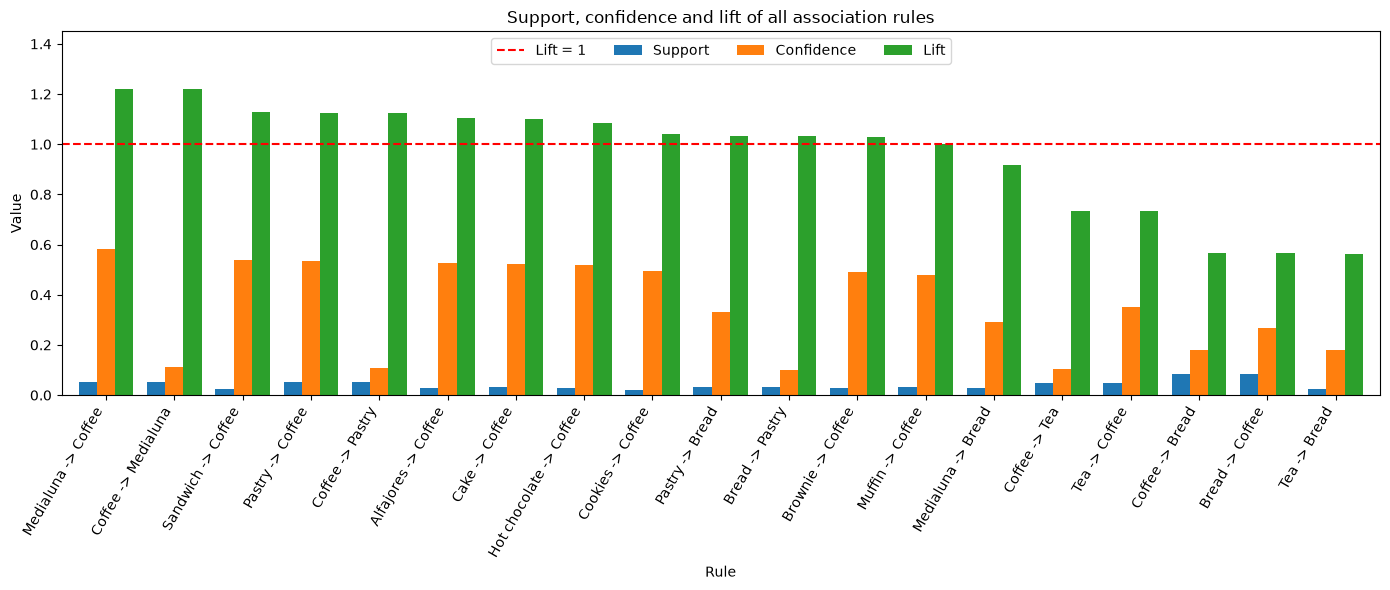

In [22]:
import matplotlib.pyplot as plt

# rule label in the form 'Left_side -> Right_side'
result_df['Rule'] = result_df['Left_side'] + ' -> ' + result_df['Right_side']

# support, confidence and lift of all rules, sorted by lift
ax = result_df.sort_values(by='Lift', ascending=False).plot(
    x='Rule', y=['Support', 'Confidence', 'Lift'], kind='bar', width=0.8, figsize=(14, 6))
ax.axhline(1, color='red', linestyle='--', label='Lift = 1')
ax.set_title('Support, confidence and lift of all association rules')
ax.set_xlabel('Rule')
ax.set_ylabel('Value')
ax.set_ylim(0, 1.45)
ax.legend(loc='upper center', ncol=4)
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

### Q3.2 Rules with lift >= 1

In [23]:
# lift >= 1: the items are bought together at least as often as expected by chance
positive_rules = result_df[result_df['Lift'] >= 1].sort_values(by='Lift', ascending=False)
print("Number of rules with lift >= 1:", len(positive_rules))
print(positive_rules[['Left_side', 'Right_side', 'Support', 'Confidence', 'Lift']].to_string())

Number of rules with lift >= 1: 13
        Left_side Right_side   Support  Confidence      Lift
15      Medialuna     Coffee  0.054261    0.582031  1.220976
14         Coffee  Medialuna  0.054261    0.113827  1.220976
19       Sandwich     Coffee  0.026220    0.537313  1.127168
18         Pastry     Coffee  0.052076    0.535581  1.123533
17         Coffee     Pastry  0.052076    0.109244  1.123533
3       Alfajores     Coffee  0.028405    0.527027  1.105589
11           Cake     Coffee  0.031318    0.524390  1.100058
13  Hot chocolate     Coffee  0.026948    0.517483  1.085567
12        Cookies     Coffee  0.020757    0.495652  1.039771
8          Pastry      Bread  0.032047    0.329588  1.033161
7           Bread     Pastry  0.032047    0.100457  1.033161
10        Brownie     Coffee  0.026948    0.490066  1.028053
16         Muffin     Coffee  0.030590    0.477273  1.001215


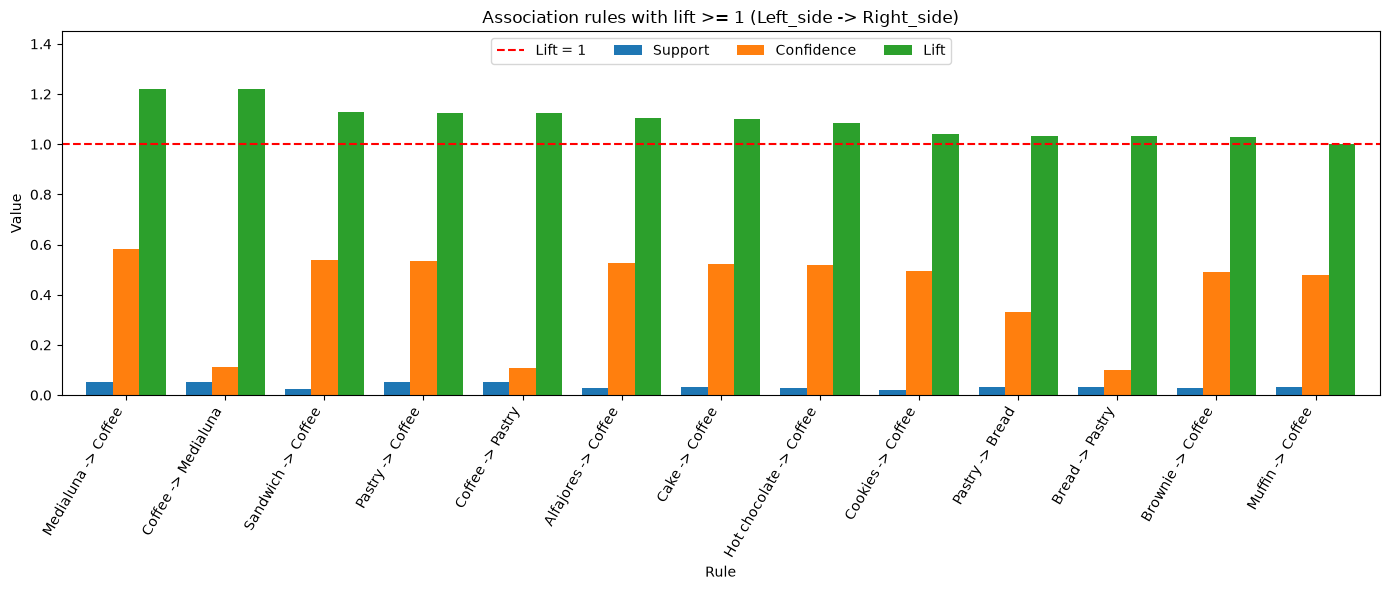

In [24]:
# plot the rules with lift >= 1, showing the Left_side and Right_side item names
ax = positive_rules.plot(
    x='Rule', y=['Support', 'Confidence', 'Lift'], kind='bar', width=0.8, figsize=(14, 6))
ax.axhline(1, color='red', linestyle='--', label='Lift = 1')
ax.set_title('Association rules with lift >= 1 (Left_side -> Right_side)')
ax.set_xlabel('Rule')
ax.set_ylabel('Value')
ax.set_ylim(0, 1.45)
ax.legend(loc='upper center', ncol=4)
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

### Q3.3 Interpretation of three positive association rules

In [25]:
# three strongest positive rules (highest lift, one direction per item pair)
print(positive_rules[positive_rules['Rule'].isin(['Medialuna -> Coffee', 'Sandwich -> Coffee', 'Pastry -> Coffee'])]
      [['Left_side', 'Right_side', 'Support', 'Confidence', 'Lift']].to_string())

    Left_side Right_side   Support  Confidence      Lift
15  Medialuna     Coffee  0.054261    0.582031  1.220976
19   Sandwich     Coffee  0.026220    0.537313  1.127168
18     Pastry     Coffee  0.052076    0.535581  1.123533


1. **Medialuna -> Coffee** (support 0.054, confidence 0.582, lift 1.221): 5.4% of all transactions contain both items, 58.2% of customers who buy a Medialuna also buy Coffee, and they are 22% more likely to buy Coffee than an average customer. This is the strongest association in the rule set.
2. **Sandwich -> Coffee** (support 0.026, confidence 0.537, lift 1.127): 53.7% of Sandwich buyers also buy Coffee, 12.7% more likely than an average customer, which suggests a lunch combination.
3. **Pastry -> Coffee** (support 0.052, confidence 0.536, lift 1.124): 53.6% of Pastry buyers also buy Coffee, 12.4% more likely than an average customer, a typical breakfast pairing.

## Q4. Products purchased with 'Pastry'

### Q4(a) Subset of rules with 'Pastry' on the Left_side

In [26]:
# rules of the form Pastry -> X (every rule from Q2 has a single item on the Left_side)
pastry_rules = result_df[result_df['Left_side'] == 'Pastry']
print("Number of rules in the subset:", len(pastry_rules))

Number of rules in the subset: 2


### Q4(b) Products most likely purchased with 'Pastry'

In [27]:
# sort descending by confidence: probability of buying the Right_side item given Pastry is bought
pastry_rules = pastry_rules.sort_values(by='Confidence', ascending=False)
print(pastry_rules[['Left_side', 'Right_side', 'Support', 'Confidence', 'Lift']].to_string())

   Left_side Right_side   Support  Confidence      Lift
18    Pastry     Coffee  0.052076    0.535581  1.123533
8     Pastry      Bread  0.032047    0.329588  1.033161


## Q5. Boosting the sales of 'Medialuna'

In [28]:
# all rules involving Medialuna, sorted by lift
medialuna_rules = result_df[(result_df['Left_side'] == 'Medialuna') | (result_df['Right_side'] == 'Medialuna')]
print(medialuna_rules.sort_values(by='Lift', ascending=False)[['Left_side', 'Right_side', 'Support', 'Confidence', 'Lift']].to_string())

    Left_side Right_side   Support  Confidence      Lift
15  Medialuna     Coffee  0.054261    0.582031  1.220976
14     Coffee  Medialuna  0.054261    0.113827  1.220976
6   Medialuna      Bread  0.027312    0.292969  0.918370


**Recommendation: place Medialuna next to Coffee.**

Coffee -> Medialuna is the only rule with medialuna on the Right_side and its lift (1.221) is the highest in the whole set. This suggests that coffee buyers are 22% more likely to buy a medialuna than an average customer. Its confidence is only 0.114 because coffee is bought in 48% of all transactions, but this also means placing medialuna near coffee exposes it to the largest group of customers in the bakery. The reverse rule Medialuna -> Coffee with confidence 0.582 confirms that the two products are strongly bought together in both directions. Bread should not be used for this purpose, since Medialuna -> Bread has lift 0.918 (less than 1), meaning the two items are bought together less often than expected by chance.